In [136]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from statsmodels.stats.multitest import fdrcorrection as fdr

In [84]:
df_PD = pd.read_csv('~/MinaRyten/Melissa/MRIxST/stats/04c-4layers_PDpredictions_withendo_with_PrD/Projected_PD_cell_counts_no_SWM.csv')
df_control = pd.read_csv('~/MinaRyten/Melissa/MRIxST/processed_data/01b-4layers_withendo/02-top3_cells_counts/top3_cells_per_layer_count.csv', index_col = 0)

In [85]:
df_control['region'] = df_control['sample_id'].str.split('_', expand = True)[1]
df_control = df_control.groupby(['bayesSpace_harmony_7', 'variable', 'region']).median()
df_control.reset_index(inplace = True)
df_control.replace({'ant':'anterior', 'mid':'middle', 'post':'posterior'}, inplace = True)

In [86]:
df_PD = pd.melt(df_PD, id_vars=['SpD', 'region'], value_vars=['Astro_PD_predicted', 'Micro_PD_predicted', 'Oligo_PD_predicted', 'OPC_PD_predicted'])
df_PD['celltype'] = df_PD['variable'].str.split('_', expand = True)[0]
df_PD.rename(columns = { 'value':'PD - predicted counts'}, inplace = True)

In [87]:
df_control.rename(columns = {'bayesSpace_harmony_7':'SpD', 'variable':'celltype', 'value':'Control - real counts'}, inplace = True)
df_control = df_control[df_control['SpD']!='WM']
df_control['key'] = df_control['SpD']+df_control['celltype']+df_control['region']

In [88]:
df_PD = df_PD[['SpD','celltype','region', 'PD - predicted counts']]
df_PD['key'] = df_PD['SpD']+df_PD['celltype']+df_PD['region']

In [89]:
#df = pd.concat([df_control, df_PD])

combined = df_PD.merge(df_control[['key', 'Control - real counts']], left_on = 'key', right_on = 'key', how = 'inner')
combined.drop(columns = 'key', inplace = True)

In [90]:
combined

,SpD,celltype,region,PD - predicted counts,Control - real counts
0,SpD4,Astro,anterior,12.640845,33.0
1,SpD3,Astro,anterior,39.545157,34.5
2,SpD2,Astro,anterior,41.397680,35.0
3,SpD1,Astro,anterior,185.018802,127.0
4,SpD4,Astro,middle,7.630877,46.0
5,SpD3,Astro,middle,68.323911,46.0
6,SpD2,Astro,middle,65.781859,53.0
7,SpD1,Astro,middle,188.590345,134.0
8,SpD4,Astro,posterior,14.452205,54.5
9,SpD3,Astro,posterior,66.895138,40.0


Cell type: Astro
R²: 0.8111395065487416
p-value: 6.443902790382335e-05


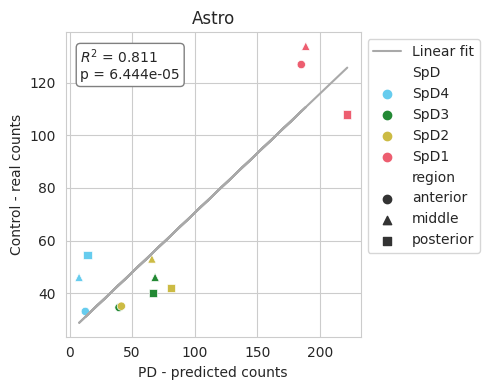

Cell type: Micro
R²: 0.5440192440290899
p-value: 0.006183643163161238


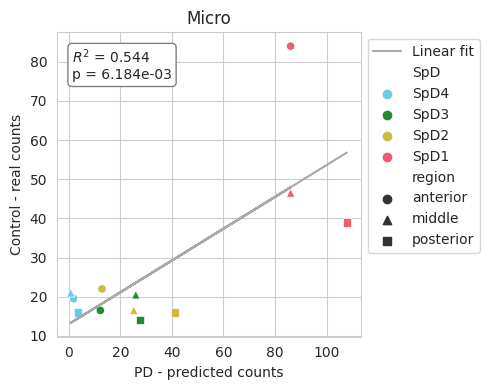

Cell type: Oligo
R²: 0.13722324416741583
p-value: 0.23588383896812762


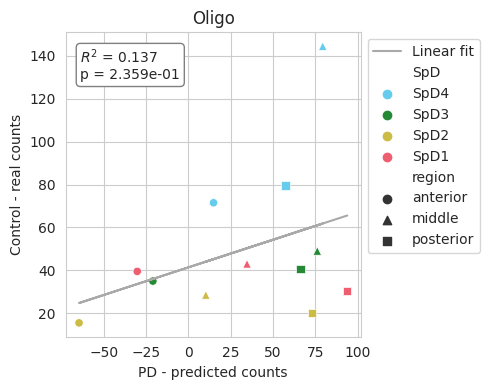

Cell type: OPC
R²: 0.4684913620931218
p-value: 0.014072256604670645


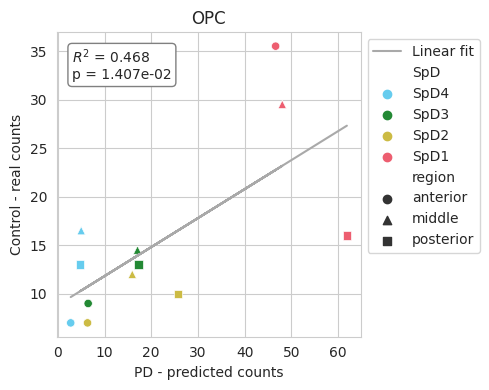

In [143]:
custom_palette = {
    'SpD1': '#ED5E70',  # blue
    'SpD2': '#CCBB44',  # orange
    'SpD3': '#238934',  # green
    'SpD4': '#66CCEE'   # red
}

marker_dict = {
    'anterior': 'o',   # circle
    'middle': '^',     # triangle
    'posterior': 's'   # square
}


sns.set_style("whitegrid")

for cell in combined['celltype'].unique():
    res = []
    print(f"Cell type: {cell}")
    
    # Subset data
    df = combined[combined['celltype'] == cell]
    X = np.asarray(df["PD - predicted counts"]).reshape(-1, 1)
    Y = np.asarray(df["Control - real counts"]).reshape(-1, 1)
    
    # Fit model
    model = LinearRegression().fit(X, Y)
    
    # R² score
    r_squared = model.score(X, Y)
    print("R²:", r_squared)
    
    
    # Add intercept
    X_sm = sm.add_constant(X)
    sm_model = sm.OLS(Y, X_sm).fit()
    p_value = sm_model.pvalues[1]  # p-value for the slope
    print("p-value:", p_value)
    
    r2_text = f"$R^2$ = {r_squared:.3f}"
    pval_text = f"p = {p_value:.3e}"

    res.append(cell)
    res.append(r_squared)
    res.append(p_value)
    
    # Plot
    plt.figure(figsize=(5, 4))
    plt.plot(X, model.predict(X), color='darkgrey', label='Linear fit')
    ax = sns.scatterplot(x=df["PD - predicted counts"], y=df["Control - real counts"], hue=df["SpD"], palette = custom_palette, style=df["region"], markers=marker_dict)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.title(f"{cell}")
    plt.xlabel("PD - predicted counts")
    plt.ylabel("Control - real counts")
    plt.tight_layout()
    
    plt.text(
    x=0.05, y=0.95,               # relative position in axes coordinates
    s=f"{r2_text}\n{pval_text}", # multiline annotation
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray"))
    plt.show()
    
    if (cell == 'Astro'):
        full_results = pd.DataFrame(res).T
    else:
        full_results = pd.concat([full_results, pd.DataFrame(res).T])



In [145]:
full_results.rename(columns = {0:'cell type', 1:'R2', 2:'pval'}, inplace = True)
full_results['padj'] = list(pd.DataFrame(fdr(full_results['pval'], alpha=0.05, method='indep', is_sorted=False)).T[1])
full_results.set_index('cell type', inplace = True)

Cell type: Astro


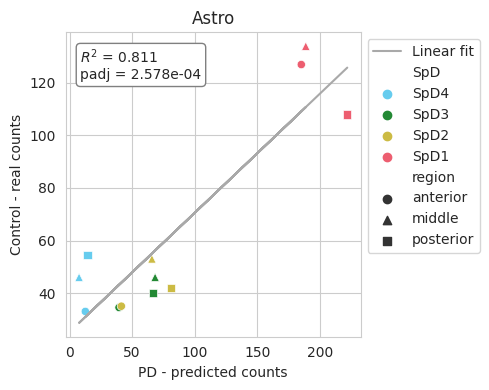

Cell type: Micro


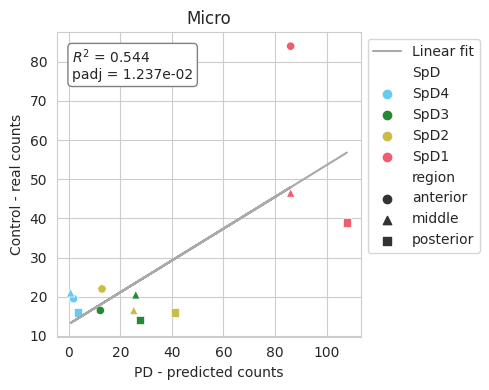

Cell type: Oligo


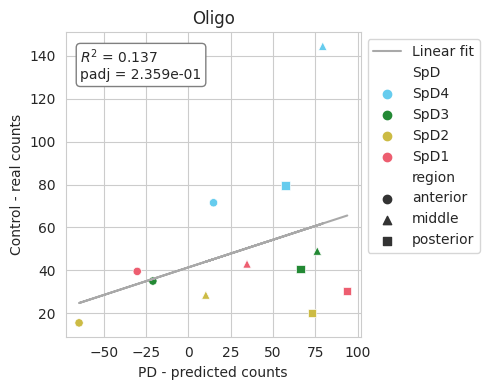

Cell type: OPC


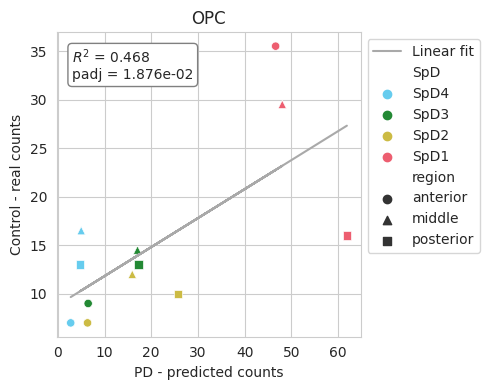

In [151]:
for cell in combined['celltype'].unique():
    res = []
    print(f"Cell type: {cell}")
    
    # Subset data
    df = combined[combined['celltype'] == cell]
    X = np.asarray(df["PD - predicted counts"]).reshape(-1, 1)
    Y = np.asarray(df["Control - real counts"]).reshape(-1, 1)
    
    r2_text = f"$R^2$ = {full_results.loc[cell]['R2']:.3f}"
    pval_text = f"padj = {full_results.loc[cell]['padj']:.3e}"
    
    # Fit model
    model = LinearRegression().fit(X, Y)
    
    # Plot
    plt.figure(figsize=(5, 4))
    plt.plot(X, model.predict(X), color='darkgrey', label='Linear fit')
    ax = sns.scatterplot(x=df["PD - predicted counts"], y=df["Control - real counts"], hue=df["SpD"], palette = custom_palette, style=df["region"], markers=marker_dict)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.title(f"{cell}")
    plt.xlabel("PD - predicted counts")
    plt.ylabel("Control - real counts")
    plt.tight_layout()
    
    plt.text(
    x=0.05, y=0.95,               # relative position in axes coordinates
    s=f"{r2_text}\n{pval_text}", # multiline annotation
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray"))
    plt.savefig('../../plots/04-visualisations/%s_celltype_predictions_PD.png' % cell, dpi = 300, bbox_inches = 'tight')
    plt.show()
    